# Assignment No. 2: Data Cleaning and Preprocessing

## 1. Introduction

Data cleaning and preprocessing are important steps in data analysis because real-world datasets may contain missing values, duplicate records, inconsistent categories, and unusual numerical values. These problems can affect the quality and reliability of data analysis.

In this assignment, the Titanic passenger dataset from Kaggle is used to demonstrate the main steps of data cleaning and preprocessing. The dataset is inspected, cleaned where necessary, and prepared for further analysis using Python, Pandas, and Scikit-learn.

The main objective is to understand the quality of the dataset, handle data-related problems appropriately, transform categorical and numerical features, and prepare the data for a potential machine learning task without causing data leakage.

## 2. Dataset Description

**Dataset Title:** Titanic - Machine Learning from Disaster

**Source:** Kaggle

**Dataset Link:** https://www.kaggle.com/competitions/titanic/data

**File Used:** train.csv

The training dataset contains information about passengers who travelled on the Titanic. It includes passenger class, name, sex, age, number of siblings or spouses aboard, number of parents or children aboard, ticket information, fare, cabin, port of embarkation, and survival status.

The original training dataset contains 891 rows and 12 columns. The target variable is Survived, where 0 represents a passenger who did not survive and 1 represents a passenger who survived.

The objective of this assignment is to identify data quality issues and prepare the dataset for reliable analysis.

In [1]:

# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")


Saving train.csv to train.csv
Dataset loaded successfully!


## 3. Initial Data Inspection

The dataset is inspected before cleaning to understand its structure, dimensions, data types, and overall quality. This step helps identify missing values, duplicate records, and potential inconsistencies before any changes are made.

In [3]:

# Display the first five rows
display(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Inspect data types and non-null counts
print("\nDataset information:")
df.info()

# Summary of numerical columns
display(df.describe())

# Summary of all columns
display(df.describe(include="all"))


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


## 4. Identification and Handling of Missing Values

Missing values can reduce the quality of analysis and may cause errors in some preprocessing methods. The number and percentage of missing values are calculated for each column.

The Age column is expected to contain missing values, while Embarked may have a small number of missing entries. Cabin may have a substantial amount of missing data. The appropriate treatment is selected after examining the actual missing-value counts.

In [4]:

# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing-value percentages
missing_percent = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percent.round(2)
})

display(missing_summary)


,Missing Values,Missing Percentage
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


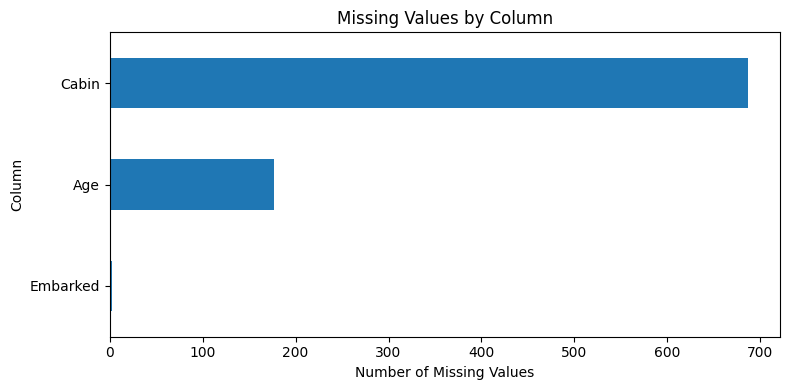

In [5]:

missing_count[missing_count > 0].sort_values().plot(
    kind="barh",
    figsize=(8, 4),
    title="Missing Values by Column"
)

plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()


## 5. Duplicate Record Detection and Removal

Duplicate records can lead to repeated observations and may distort statistical summaries. Exact duplicate rows are identified and counted. If duplicates are found, they are removed. If no duplicate rows exist, the dataset is retained without unnecessary deletion.

In [6]:

# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Remove exact duplicate rows if present
df = df.drop_duplicates().copy()

print("Shape after duplicate handling:", df.shape)


Number of duplicate rows: 0
Shape after duplicate handling: (891, 12)


## 6. Handling Inconsistent Values and Data Types

Categorical values are checked for extra spaces, inconsistent capitalization, and unexpected categories. Leading and trailing spaces are removed, and text categories are standardized where appropriate.

Numerical columns are checked to ensure that their values are stored using appropriate numerical data types. The Survived column is retained as a binary target variable, while PassengerId is treated as an identifier rather than a predictive feature.

In [7]:

# Display categorical values before cleaning
for col in ["Sex", "Embarked"]:
    print(f"\nUnique values in {col}:")
    print(df[col].value_counts(dropna=False))

# Standardize text formatting
for col in ["Sex", "Embarked"]:
    df[col] = df[col].apply(
        lambda x: x.strip().lower() if isinstance(x, str) else x
    )

# Restore consistent category capitalization
df["Sex"] = df["Sex"].replace({
    "male": "Male",
    "female": "Female"
})

df["Embarked"] = df["Embarked"].replace({
    "c": "C",
    "q": "Q",
    "s": "S"
})

# Check data types
print("\nData types after checking:")
print(df.dtypes)

# Validate important numerical columns
for col in ["PassengerId", "Pclass", "Age", "SibSp",
            "Parch", "Fare", "Survived"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nMissing values after type conversion:")
print(df.isnull().sum())



Unique values in Sex:
Sex
male      577
female    314
Name: count, dtype: int64

Unique values in Embarked:
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

Data types after checking:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Missing values after type conversion:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


## 7. Outlier Detection Using the IQR Method

Outliers are observations that differ considerably from the general distribution of a numerical feature. The Interquartile Range (IQR) method is used to identify potential outliers in Age and Fare.

The IQR is calculated as the third quartile minus the first quartile. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers.

A flagged observation is not automatically considered an error. Unusually high ticket fares or passenger ages may be valid. Therefore, potential outliers are inspected, and valid observations are retained.

In [8]:

# Identify potential outliers using IQR
for col in ["Age", "Fare"]:
    values = df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Potential outliers:", len(outliers))
    print("Minimum:", values.min())
    print("Maximum:", values.max())



Column: Age
Lower bound: -6.69
Upper bound: 64.81
Potential outliers: 11
Minimum: 0.42
Maximum: 80.0

Column: Fare
Lower bound: -26.72
Upper bound: 65.63
Potential outliers: 116
Minimum: 0.0
Maximum: 512.3292


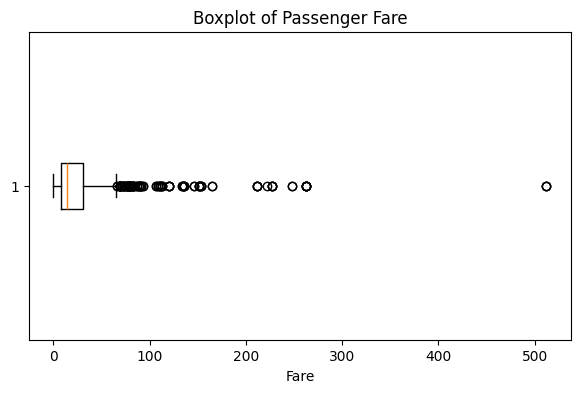

In [9]:

plt.figure(figsize=(7, 4))
plt.boxplot(df["Fare"].dropna(), vert=False)
plt.title("Boxplot of Passenger Fare")
plt.xlabel("Fare")
plt.show()


## 8. Feature and Target Identification

The target variable is Survived because it indicates whether a passenger survived the disaster. The remaining useful passenger characteristics are treated as potential input features.

PassengerId is an identifier and is excluded from the model features. Name, Ticket, and Cabin are also excluded from the initial preprocessing pipeline because they require additional feature extraction or contain information that is not being directly modelled in this assignment.

The original Pclass variable represents an ordinal category because its values indicate passenger classes. Sex and Embarked are categorical variables, while Age, Fare, SibSp, and Parch are numerical variables. Survived is a binary target variable.

In [10]:

# Identify variables by type
print("Numerical variables:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical variables:")
print(df.select_dtypes(include="object").columns.tolist())

print("\nBinary target distribution:")
print(df["Survived"].value_counts(dropna=False))


Numerical variables:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Categorical variables:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']

Binary target distribution:
Survived
0    549
1    342
Name: count, dtype: int64


## 9. Feature Engineering and Transformation

Feature engineering creates additional variables that may provide useful information. FamilySize is created by adding SibSp and Parch to one, representing the passenger and their accompanying family members. IsAlone indicates whether the passenger was travelling without accompanying family members.

The Fare variable is examined for skewness. Since ticket fares may be strongly right-skewed, a log1p transformation is applied to reduce skewness. This transformation is appropriate for non-negative fare values and is performed before scaling the numerical features.

In [11]:

# Check Fare skewness before transformation
print("Fare skewness before transformation:",
      round(df["Fare"].skew(), 3))

# Create useful derived features
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Fare should be non-negative for log1p
if (df["Fare"].dropna() < 0).any():
    raise ValueError("Negative fare values require investigation.")

# Apply log transformation
df["Fare_log"] = np.log1p(df["Fare"])

print("Fare skewness after transformation:",
      round(df["Fare_log"].skew(), 3))

display(df[[
    "SibSp", "Parch", "FamilySize", "IsAlone",
    "Fare", "Fare_log"
]].head())


Fare skewness before transformation: 4.787
Fare skewness after transformation: 0.395


,SibSp,Parch,FamilySize,IsAlone,Fare,Fare_log
0,1,0,2,0,7.2500,2.110213
1,1,0,2,0,71.2833,4.280593
2,0,0,1,1,7.9250,2.188856
3,1,0,2,0,53.1000,3.990834
4,0,0,1,1,8.0500,2.202765


## 10. Encoding, Imputation, and Standardization

Numerical and categorical features require different preprocessing methods. Missing numerical values are imputed using the median because it is less sensitive to extreme values than the mean. Missing categorical values are imputed using the most frequent category.

Sex and Embarked are nominal categorical variables, so One-Hot Encoding is applied to convert them into numerical indicator columns. Numerical features are standardized using StandardScaler so that their scales are more comparable.

The dataset is split into training and testing subsets before fitting the preprocessing pipeline. Imputation statistics, category mappings, and scaling parameters are learned only from the training data. This prevents information from the test set from leaking into the training process.

In [12]:

# Create modelling features and target
target = "Survived"

numeric_features = [
    "Pclass", "Age", "SibSp", "Parch",
    "Fare_log", "FamilySize", "IsAlone"
]

categorical_features = ["Sex", "Embarked"]

X = df[numeric_features + categorical_features].copy()
y = df[target].copy()

# Split before fitting preprocessing methods
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training feature shape: (712, 9)
Testing feature shape: (179, 9)
Training target shape: (712,)
Testing target shape: (179,)


In [13]:

# Numerical preprocessing:
# Fill missing values using median, then standardize
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# Fill missing values using mode, then one-hot encode
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct pipeline to each feature type
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

# Learn preprocessing parameters only from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting on it
X_test_processed = preprocessor.transform(X_test)

# Retrieve processed feature names
feature_names = preprocessor.get_feature_names_out()

print("Preprocessing completed.")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Number of processed features:", len(feature_names))
print("\nProcessed feature names:")
print(feature_names.tolist())


Preprocessing completed.
Processed training shape: (712, 12)
Processed testing shape: (179, 12)
Number of processed features: 12

Processed feature names:
['num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__Fare_log', 'num__FamilySize', 'num__IsAlone', 'cat__Sex_Female', 'cat__Sex_Male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S']


## 11. Final Data Quality Checks

After preprocessing, the transformed datasets are checked to confirm that the pipeline has handled missing values and converted the selected features into a numerical representation. The final training and testing dimensions are recorded.

The original dataset is retained for interpretation, while the processed matrices are used for downstream analysis. The training and testing subsets remain separate to maintain a leakage-safe preprocessing workflow.

In [14]:

# Check that preprocessing produced finite numerical values
train_array = X_train_processed.toarray() if hasattr(
    X_train_processed, "toarray"
) else np.asarray(X_train_processed)

test_array = X_test_processed.toarray() if hasattr(
    X_test_processed, "toarray"
) else np.asarray(X_test_processed)

print("Missing values in processed training data:",
      np.isnan(train_array).sum())

print("Missing values in processed testing data:",
      np.isnan(test_array).sum())

print("Infinite values in training data:",
      np.isinf(train_array).sum())

print("Infinite values in testing data:",
      np.isinf(test_array).sum())

print("\nFinal training rows:", X_train_processed.shape[0])
print("Final testing rows:", X_test_processed.shape[0])
print("Final feature count:", X_train_processed.shape[1])

# Display a small sample of the processed training data
processed_preview = pd.DataFrame(
    train_array[:5],
    columns=feature_names
)

display(processed_preview)


Missing values in processed training data: 0
Missing values in processed testing data: 0
Infinite values in training data: 0
Infinite values in testing data: 0

Final training rows: 712
Final testing rows: 179
Final feature count: 12


,num__Pclass,num__Age,num__SibSp,num__Parch,num__Fare_log,num__FamilySize,num__IsAlone,cat__Sex_Female,cat__Sex_Male,cat__Embarked_C,cat__Embarked_Q,cat__Embarked_S
0,0.829568,-0.081135,-0.465084,-0.466183,1.124592,-0.556339,0.800346,0.0,1.0,0.0,0.0,1.0
1,-0.370945,-0.081135,-0.465084,-0.466183,-3.014278,-0.556339,0.800346,0.0,1.0,0.0,0.0,1.0
2,-1.571457,-0.081135,-0.465084,-0.466183,2.508198,-0.556339,0.800346,0.0,1.0,0.0,0.0,1.0
3,0.829568,-0.887827,-0.465084,0.727782,-0.627019,0.073412,-1.249460,1.0,0.0,0.0,0.0,1.0
4,-0.370945,0.110934,0.478335,0.727782,0.361872,0.703162,-1.249460,1.0,0.0,0.0,0.0,1.0


## 12. Saving the Preprocessed Data

The processed training and testing datasets are saved as CSV files so they can be reused in further analysis. The target variable is saved separately for both subsets. The preprocessing pipeline is also saved to preserve the fitted imputers, encoder, and scaling parameters.

These files make the preprocessing process reproducible and allow the same transformations to be applied to future data.

In [15]:

# Convert processed matrices to DataFrames
X_train_df = pd.DataFrame(
    train_array,
    columns=feature_names
)

X_test_df = pd.DataFrame(
    test_array,
    columns=feature_names
)

# Save processed features
X_train_df.to_csv("X_train_processed.csv", index=False)
X_test_df.to_csv("X_test_processed.csv", index=False)

# Save corresponding targets
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

# Save the fitted preprocessing pipeline
import joblib

joblib.dump(preprocessor, "preprocessing_pipeline.joblib")

print("Processed files saved successfully.")


Processed files saved successfully.


## 13. Conclusion

This assignment demonstrated the main steps involved in cleaning and preprocessing the Titanic passenger dataset. The data was inspected to identify missing values, duplicate records, categorical inconsistencies, and potential outliers. Appropriate data types were checked, and useful derived features were created.

The IQR method was used to identify potential outliers without automatically removing valid observations. A log transformation was applied to the Fare feature to reduce skewness. Numerical features were imputed and standardized, while categorical features were imputed and one-hot encoded.

The preprocessing pipeline was fitted only on the training subset and then applied to the testing subset, reducing the risk of data leakage. Final checks were performed to verify the processed data.

This assignment demonstrates that careful data cleaning and preprocessing improve data quality and prepare datasets for reliable future analysis and machine learning.